# Pairwise AUC-Matched Neural Commitment-Time Lead–Lag Heatmaps

This notebook computes and visualises pairwise lead–lag relationships between
brain regions, using neural commitment times (nTc) derived from AUC-matched
unit populations.

For every ordered region pair (A, B), a pairwise CSV supplies the
click-relative commitment times for both regions on the same set of
AUC-matched trials. The notebook then asks: on what fraction of trials does
region A commit before region B?

**Tie handling.** Lead percentages are computed *excluding* tied trials
(i.e., the denominator is only trials where the two regions have different
commitment times). Separate tie-fraction heatmaps are generated to quantify
the prevalence of ties.

**Reading the heatmaps.** Each cell (row, col) shows the percentage of
non-tied trials on which the *row* region committed before the *column*
region. Because ties are excluded from both sides, entry (A, B) and entry
(B, A) sum to exactly 100 %.

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── Font configuration ────────────────────────────────────────────────────────
_FONT_NAME = "Helvetica"

plt.rcParams.update({
    "figure.dpi": 150,
    "font.family": _FONT_NAME,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.titlesize": 15,
})

# ── Brain-region display colours (RGB, 0–1 scale) ────────────────────────────
REGION_COLORS = {
    "dmFC": (0, 0, 1),
    "M1":   (1, 0, 0),
    "ADS":  (0, 0, 0.17),
    "S1":   (1, 0.1, 0.72),
    "mPFC": (0, 1, 0),
    "BLA":  (0, 1, 0.76),
    "TS":   (1, 0.83, 0),
    "MGB":  (0.52, 0.52, 1),
    "NAc":  (0.62, 0.31, 0.28),
    "HPC":  (0, 0.34, 0),
    "CC":   (0, 0.52, 0.59),
    "SBN":  (0, 0, 0.48),
    "DS":   (0.59, 0.83, 0.31),
    "V1":   (0.97, 0.62, 0.86),
    "GP":   (0.83, 0.07, 1),
    "Pir":  (0.48, 0.1, 0.41),
    "PP":   (0.97, 0.07, 0.38),
    "SN":   (1, 0.76, 0.52),
    "all":  (0.5, 0.5, 0.5),
}

# ── Paths ─────────────────────────────────────────────────────────────────────
DATA_DIR = Path(
    r"/Users/jc2988/Documents/GitHub/uberphys/julie/analyses/"
    r"2026_04_22_AUCmatchedrank"
)
PAIRWISE_GLOB = "matched_units_*_nTc_results_paper_compare.csv"

FIG_DIR = Path(".") / "figures"
FIG_DIR.mkdir(exist_ok=True)

# ── Analysis parameters ──────────────────────────────────────────────────────
CANONICAL_REGIONS = [
    "M1", "ADS", "dmFC", "MGB", "mPFC", "TS", "HPC", "S1", "BLA", "NAc",
]
HEATMAP_VMIN = 0.0
HEATMAP_VMAX = 100.0
HEATMAP_CMAP = "RdBu"  # 0 % → blue, 50 % → white, 100 % → red

print(f"Pairwise CSV folder : {DATA_DIR}")
print(f"Figure directory    : {FIG_DIR}")
print(f"Shared colour scale : {HEATMAP_VMIN:.0f} % to {HEATMAP_VMAX:.0f} %")

Pairwise CSV folder : /Users/jc2988/Documents/GitHub/uberphys/julie/analyses/2026_04_22_AUCmatchedrank
Figure directory    : figures
Shared colour scale : 0 % to 100 %


## Load pairwise AUC-matched CSVs

In [11]:
def parse_pair_regions(csv_path):
    """Extract the ordered (region_a, region_b) tuple from a pairwise CSV filename.

    Expected pattern:
        matched_units_<regionA>_<regionB>_nTc_results_paper_compare.csv
    """
    pair_token = (
        csv_path.stem
        .replace("matched_units_", "")
        .replace("_nTc_results_paper_compare", "")
    )
    region_a, region_b = pair_token.split("_", 1)
    return region_a, region_b


def load_pairwise_tables(data_dir):
    """Load all pairwise AUC-matched nTc CSVs and return structured data.

    Returns
    -------
    pair_tables : dict of (str, str) -> DataFrame
        Per-pair DataFrames keyed by (region_a, region_b).
    pairwise_long_df : DataFrame
        All trials in long format with standardised columns.
    pairwise_summary : DataFrame
        One row per CSV with trial / session / animal counts.
    all_regions : list of str
        Subset of CANONICAL_REGIONS actually present in the loaded data.
    """
    pair_files = sorted(data_dir.glob(PAIRWISE_GLOB))
    if not pair_files:
        raise FileNotFoundError(
            f"No pairwise AUC-matched CSVs found under {data_dir}"
        )

    pair_tables = {}
    all_rows = []
    summary_rows = []
    region_set = set()

    for csv_path in pair_files:
        region_a, region_b = parse_pair_regions(csv_path)

        # Validate required columns before the full read
        header_cols = pd.read_csv(csv_path, nrows=0).columns.tolist()
        required_cols = [
            "recording_id",
            "stereoclick_time_s",
            f"our_committime_s_{region_a}",
            f"our_committime_s_{region_b}",
        ]
        missing_cols = [c for c in required_cols if c not in header_cols]
        if missing_cols:
            raise KeyError(
                f"{csv_path.name} is missing required columns: {missing_cols}"
            )

        raw_df = pd.read_csv(csv_path)

        # Retain metadata columns that are present in this CSV
        base_cols = [
            c for c in [
                "recording_id", "index_in_Trials", "index_in_session",
                "stereoclick_time_s", "movementtime_s", "gamma",
                "pair_name", "run_name",
            ]
            if c in raw_df.columns
        ]
        clean_df = raw_df[
            base_cols
            + [f"our_committime_s_{region_a}", f"our_committime_s_{region_b}"]
        ].copy()

        # Derive animal ID and click-relative commitment times
        clean_df["animal"] = (
            clean_df["recording_id"]
            .astype(str)
            .str.extract(r"^([A-Z]\d+)")[0]
        )
        clean_df["region_a"] = region_a
        clean_df["region_b"] = region_b
        clean_df[f"rel_{region_a}"] = (
            clean_df[f"our_committime_s_{region_a}"]
            - clean_df["stereoclick_time_s"]
        )
        clean_df[f"rel_{region_b}"] = (
            clean_df[f"our_committime_s_{region_b}"]
            - clean_df["stereoclick_time_s"]
        )
        # Canonical generic aliases for downstream functions
        clean_df["rel_a"] = clean_df[f"rel_{region_a}"]
        clean_df["rel_b"] = clean_df[f"rel_{region_b}"]

        pair_tables[(region_a, region_b)] = clean_df
        region_set.update([region_a, region_b])

        valid_pair_df = clean_df[["rel_a", "rel_b"]].dropna()
        summary_rows.append({
            "pair_csv": csv_path.name,
            "region_a": region_a,
            "region_b": region_b,
            "rows": len(clean_df),
            "sessions": clean_df["recording_id"].nunique(),
            "animals": clean_df["animal"].nunique(),
            "overlapping_valid_trials": len(valid_pair_df),
        })
        all_rows.append(
            clean_df[
                ["recording_id", "animal", "region_a", "region_b",
                 "rel_a", "rel_b"]
            ].assign(source_csv=csv_path.name)
        )

    pairwise_long_df = pd.concat(all_rows, ignore_index=True)
    pairwise_summary = (
        pd.DataFrame(summary_rows)
        .sort_values(["region_a", "region_b"])
        .reset_index(drop=True)
    )
    all_regions = [r for r in CANONICAL_REGIONS if r in region_set]
    return pair_tables, pairwise_long_df, pairwise_summary, all_regions


pair_tables, pairwise_long_df, pairwise_summary, ALL_REGIONS = (
    load_pairwise_tables(DATA_DIR)
)
ALL_SESSIONS = sorted(pairwise_long_df["recording_id"].dropna().unique())
ALL_ANIMALS  = sorted(pairwise_long_df["animal"].dropna().unique())

print(f"Loaded {len(pair_tables)} pairwise AUC-matched CSVs.")
print(f"Regions represented : {ALL_REGIONS}")
print(f"Total sessions      : {len(ALL_SESSIONS)}")
print(f"Animals             : {ALL_ANIMALS}")
pairwise_summary.head()

Loaded 45 pairwise AUC-matched CSVs.
Regions represented : ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'S1', 'BLA', 'NAc']
Total sessions      : 19
Animals             : ['A324', 'A327', 'C211']


,pair_csv,region_a,region_b,rows,sessions,animals,overlapping_valid_trials
0,matched_units_ADS_BLA_nTc_results_paper_compar...,ADS,BLA,5050,12,2,532
1,matched_units_ADS_HPC_nTc_results_paper_compar...,ADS,HPC,8705,15,3,748
2,matched_units_ADS_M1_nTc_results_paper_compare...,ADS,M1,9907,19,3,1850
3,matched_units_ADS_MGB_nTc_results_paper_compar...,ADS,MGB,9907,19,3,1096
4,matched_units_ADS_NAc_nTc_results_paper_compar...,ADS,NAc,9907,19,3,565


## Region coverage by session and animal

In [12]:
def get_present_regions(scope_name, scope_column):
    """Return the subset of ALL_REGIONS with non-empty pairwise data for a given scope."""
    present = set()
    for (region_a, region_b), pair_df in pair_tables.items():
        scope_df = pair_df.loc[
            pair_df[scope_column] == scope_name, ["rel_a", "rel_b"]
        ].dropna()
        if not scope_df.empty:
            present.update([region_a, region_b])
    return [r for r in ALL_REGIONS if r in present]


print("Per-session region coverage:")
for recording_id in ALL_SESSIONS:
    regions = get_present_regions(recording_id, "recording_id")
    print(f"  {recording_id}: {regions}")

print("\nPer-animal region coverage:")
for animal in ALL_ANIMALS:
    regions = get_present_regions(animal, "animal")
    print(f"  {animal}: {regions}")

Per-session region coverage:
  A324_2023_07_19a: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'S1', 'NAc']
  A324_2023_07_20: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'S1', 'NAc']
  A324_2023_07_21: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'S1', 'NAc']
  A324_2023_07_22: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'S1', 'NAc']
  A324_2023_07_23: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'S1', 'NAc']
  A324_2023_07_24: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'S1', 'NAc']
  A324_2023_07_25: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'NAc']
  A327_2023_08_31: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'BLA', 'NAc']
  A327_2023_09_01: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'BLA', 'NAc']
  A327_2023_09_02: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'BLA', 'NAc']
  A327_2023_09_03: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'BLA', 'NAc']
  A327_2023_09_04: ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', '

## Core computation and plotting functions

In [13]:
def compute_pairwise_lead_matrices(scope_name, scope_column, regions=None):
    """Compute lead-percentage, overlap, and tie matrices for a given scope.

    Lead percentages exclude ties from the denominator:
        lead_pct(A, B) = 100 * n_A_leads / (n_A_leads + n_B_leads)

    Tie percentages use the full overlap as the denominator:
        tie_pct(A, B) = 100 * n_ties / n_overlap

    Parameters
    ----------
    scope_name : str
        Value to filter on (a recording_id or animal name).
    scope_column : str
        Column to filter ("recording_id" or "animal").
    regions : list of str, optional
        Region ordering for the output matrices.
        Defaults to CANONICAL_REGIONS.

    Returns
    -------
    tuple of six DataFrames
        (lead_pct_matrix, overlap_count_matrix, nontied_count_matrix,
         lead_count_matrix, tie_count_matrix, tie_pct_matrix)
    """
    if regions is None:
        regions = CANONICAL_REGIONS

    lead_pct_matrix      = pd.DataFrame(np.nan, index=regions, columns=regions, dtype=float)
    overlap_count_matrix = pd.DataFrame(0,      index=regions, columns=regions, dtype=int)
    nontied_count_matrix = pd.DataFrame(0,      index=regions, columns=regions, dtype=int)
    lead_count_matrix    = pd.DataFrame(0,      index=regions, columns=regions, dtype=int)
    tie_count_matrix     = pd.DataFrame(0,      index=regions, columns=regions, dtype=int)
    tie_pct_matrix       = pd.DataFrame(np.nan, index=regions, columns=regions, dtype=float)

    for (region_a, region_b), pair_df in pair_tables.items():
        # Skip pairs involving regions outside the requested set
        if region_a not in regions or region_b not in regions:
            continue

        scope_df = pair_df.loc[
            pair_df[scope_column] == scope_name, ["rel_a", "rel_b"]
        ].dropna()
        n_overlap = len(scope_df)

        overlap_count_matrix.loc[region_a, region_b] = n_overlap
        overlap_count_matrix.loc[region_b, region_a] = n_overlap

        if n_overlap == 0:
            continue

        a_leads   = int((scope_df["rel_a"] < scope_df["rel_b"]).sum())
        b_leads   = int((scope_df["rel_b"] < scope_df["rel_a"]).sum())
        ties      = int((scope_df["rel_a"] == scope_df["rel_b"]).sum())
        n_nontied = a_leads + b_leads

        assert a_leads + b_leads + ties == n_overlap, (
            f"Count mismatch for {region_a}–{region_b} in {scope_name}: "
            f"{a_leads} + {b_leads} + {ties} != {n_overlap}"
        )

        lead_count_matrix.loc[region_a, region_b]    = a_leads
        lead_count_matrix.loc[region_b, region_a]    = b_leads
        tie_count_matrix.loc[region_a, region_b]     = ties
        tie_count_matrix.loc[region_b, region_a]     = ties
        nontied_count_matrix.loc[region_a, region_b] = n_nontied
        nontied_count_matrix.loc[region_b, region_a] = n_nontied

        # Tie percentage (denominator = all overlapping trials)
        tie_pct_matrix.loc[region_a, region_b] = 100.0 * ties / n_overlap
        tie_pct_matrix.loc[region_b, region_a] = 100.0 * ties / n_overlap

        # Lead percentage (denominator = non-tied trials only)
        if n_nontied > 0:
            lead_pct_matrix.loc[region_a, region_b] = 100.0 * a_leads / n_nontied
            lead_pct_matrix.loc[region_b, region_a] = 100.0 * b_leads / n_nontied
        # else: leave as NaN (all trials were ties)

    return (
        lead_pct_matrix, overlap_count_matrix, nontied_count_matrix,
        lead_count_matrix, tie_count_matrix, tie_pct_matrix,
    )


def _format_lead_annotation(value, nontied_count):
    """Cell annotation for lead-percentage heatmaps."""
    if pd.isna(value):
        return "no data"
    return f"{value:.1f}%\n(n={int(nontied_count)})"


def _format_tie_annotation(value, overlap_count):
    """Cell annotation for tie-percentage heatmaps."""
    if pd.isna(value):
        return "no data"
    return f"{value:.1f}%\n(n={int(overlap_count)})"


def plot_pairwise_heatmap(
    matrix, count_matrix, title, colorbar_label, annotation_fn,
    vmin=HEATMAP_VMIN, vmax=HEATMAP_VMAX, cmap=HEATMAP_CMAP,
):
    """Render an annotated heatmap for a pairwise lead-% or tie-% matrix.

    Parameters
    ----------
    matrix : DataFrame
        Square matrix of percentages (NaN for missing / diagonal).
    count_matrix : DataFrame
        Matching counts displayed in the cell annotations.
    title : str
        Figure title.
    colorbar_label : str
        Label for the colour bar.
    annotation_fn : callable(value, count) -> str
        Formatter for cell text.
    vmin, vmax : float
        Colour-scale limits.
    cmap : str
        Matplotlib colourmap name.

    Returns
    -------
    fig : matplotlib.figure.Figure
    """
    n_regions = len(matrix.index)
    fig_width  = max(6.5, 0.9 * n_regions + 2.5)
    fig_height = max(5.5, 0.9 * n_regions + 1.8)
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    cmap_obj = plt.get_cmap(cmap).copy()
    cmap_obj.set_bad(color="black")
    image = ax.imshow(matrix.values, vmin=vmin, vmax=vmax, cmap=cmap_obj)

    # Colour bar
    cbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(colorbar_label, fontfamily=_FONT_NAME, fontweight="bold")
    for lbl in cbar.ax.get_yticklabels():
        lbl.set_fontfamily(_FONT_NAME)

    # Axis labels and title
    ax.set_xticks(np.arange(n_regions))
    ax.set_yticks(np.arange(n_regions))
    ax.set_xticklabels(matrix.columns, rotation=45, ha="right")
    ax.set_yticklabels(matrix.index)
    ax.set_xlabel("Column region", fontfamily=_FONT_NAME, fontweight="bold")
    ax.set_ylabel("Row region",    fontfamily=_FONT_NAME, fontweight="bold")
    ax.set_title(title, fontfamily=_FONT_NAME, fontweight="bold")

    # Colour-code tick labels by brain region
    for lbl in list(ax.get_xticklabels()) + list(ax.get_yticklabels()):
        region = lbl.get_text()
        lbl.set_fontfamily(_FONT_NAME)
        lbl.set_fontweight("bold")
        if region in REGION_COLORS:
            lbl.set_color(REGION_COLORS[region])

    # Cell annotations with adaptive text colour
    for ri, row_region in enumerate(matrix.index):
        for ci, col_region in enumerate(matrix.columns):
            cell_val  = matrix.loc[row_region, col_region]
            count_val = count_matrix.loc[row_region, col_region]
            annotation = annotation_fn(cell_val, count_val)

            if pd.isna(cell_val):
                text_colour = "white"
            else:
                norm_val = (cell_val - vmin) / (vmax - vmin) if vmax != vmin else 0.5
                bg_rgba  = cmap_obj(np.clip(norm_val, 0, 1))
                luminance = 0.299 * bg_rgba[0] + 0.587 * bg_rgba[1] + 0.114 * bg_rgba[2]
                text_colour = "black" if luminance > 0.5 else "white"

            ax.text(
                ci, ri, annotation,
                ha="center", va="center",
                color=text_colour, fontsize=8, fontfamily=_FONT_NAME,
            )

    # Grid lines between cells
    ax.set_xticks(np.arange(-0.5, n_regions, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_regions, 1), minor=True)
    ax.grid(which="minor", color="0.7", linestyle="-", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    fig.tight_layout()
    return fig

## Per-animal lead-percentage heatmaps (ties excluded)

Each cell (row, col) shows the percentage of non-tied trials on which the
row region's neural commitment time preceded the column region's. Cells
with no overlapping matched trials are shown in black.

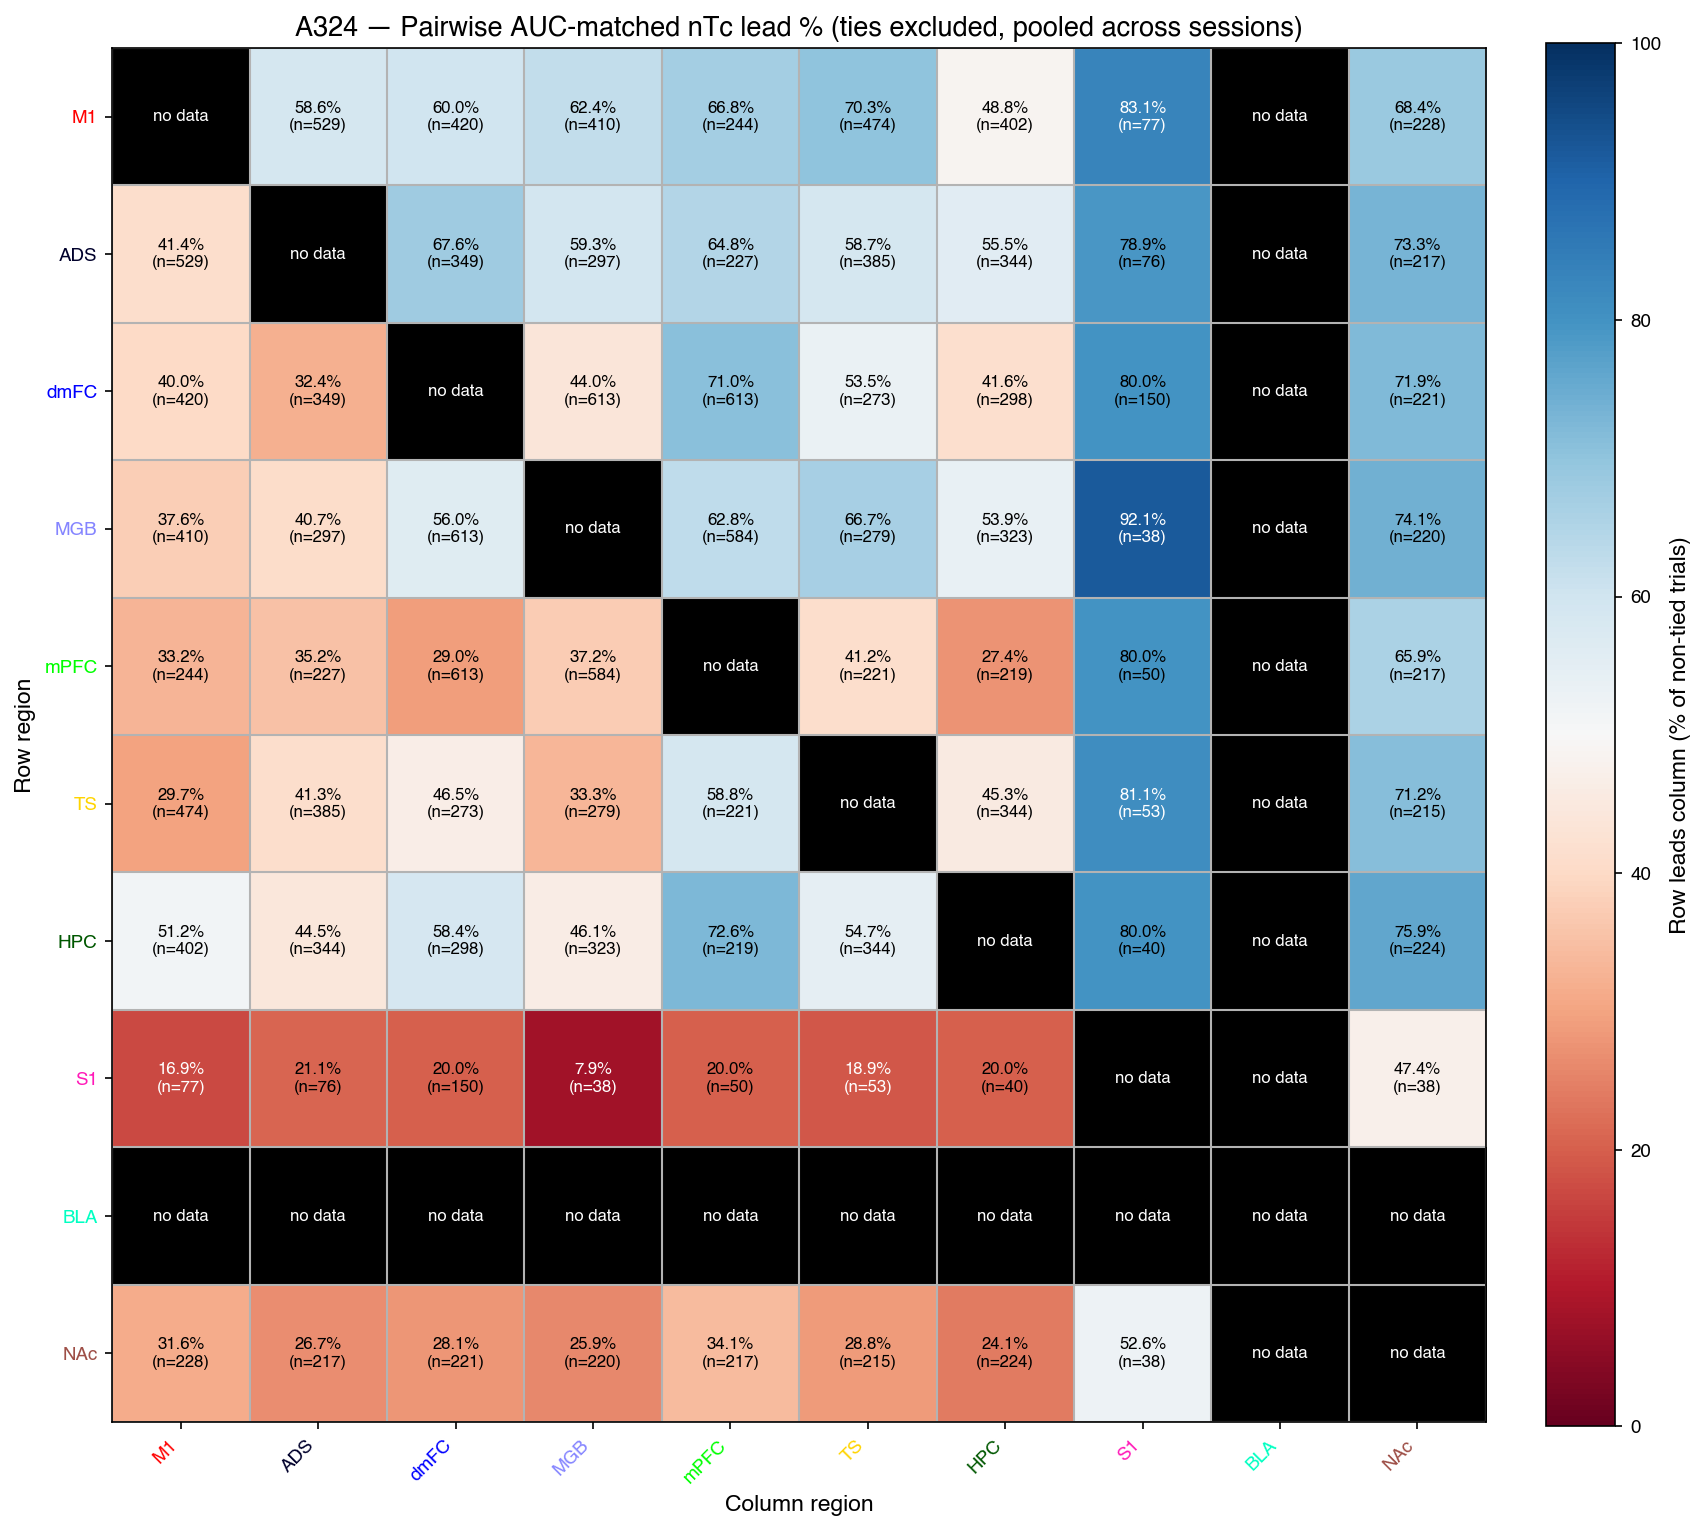

Saved: figures/pairwise_aucmatched_ntc_lead_heatmap_animal_A324.svg


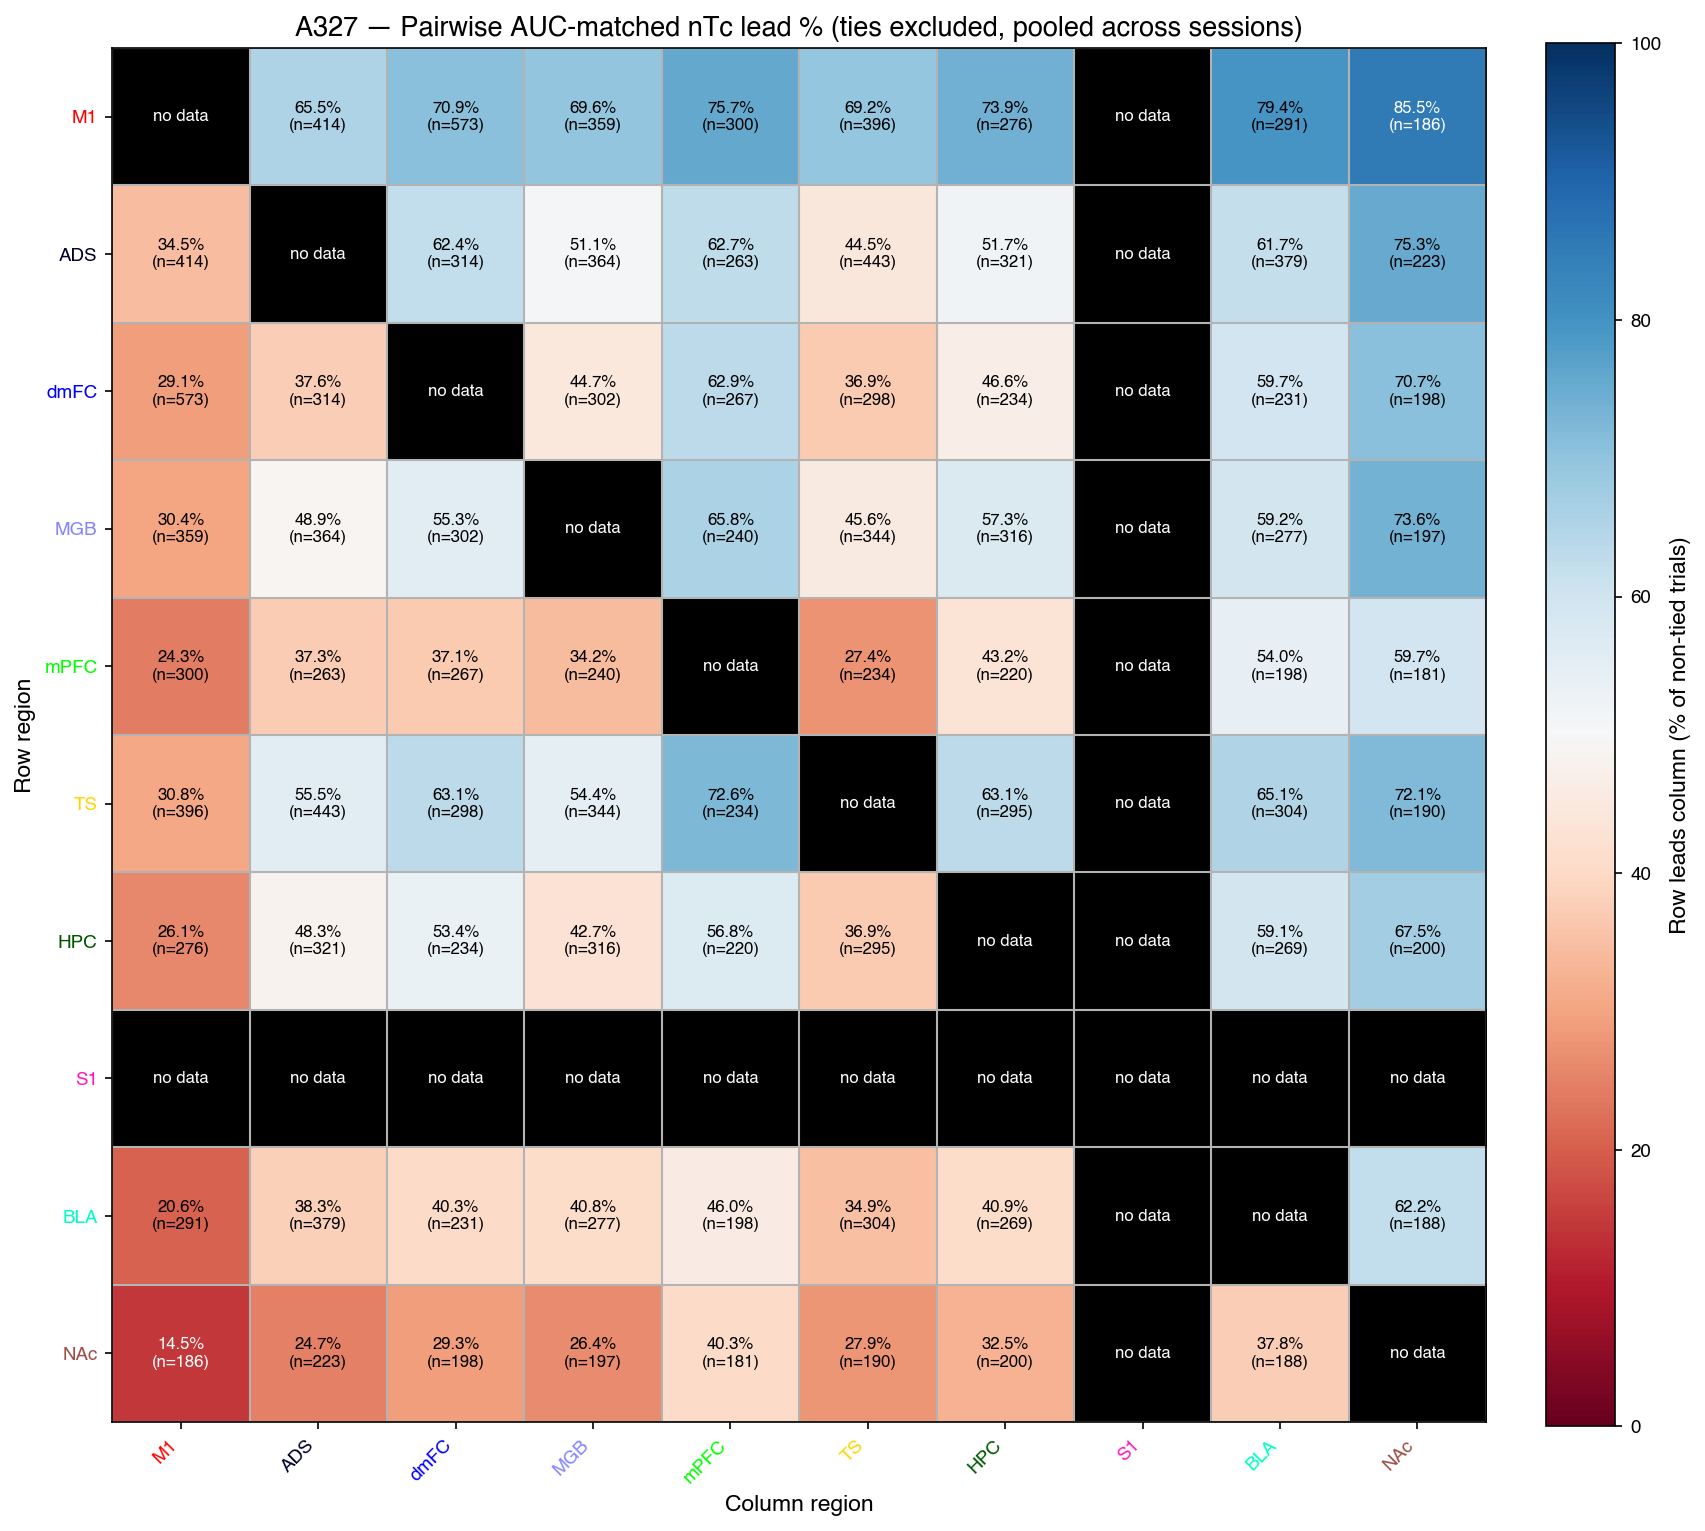

Saved: figures/pairwise_aucmatched_ntc_lead_heatmap_animal_A327.svg


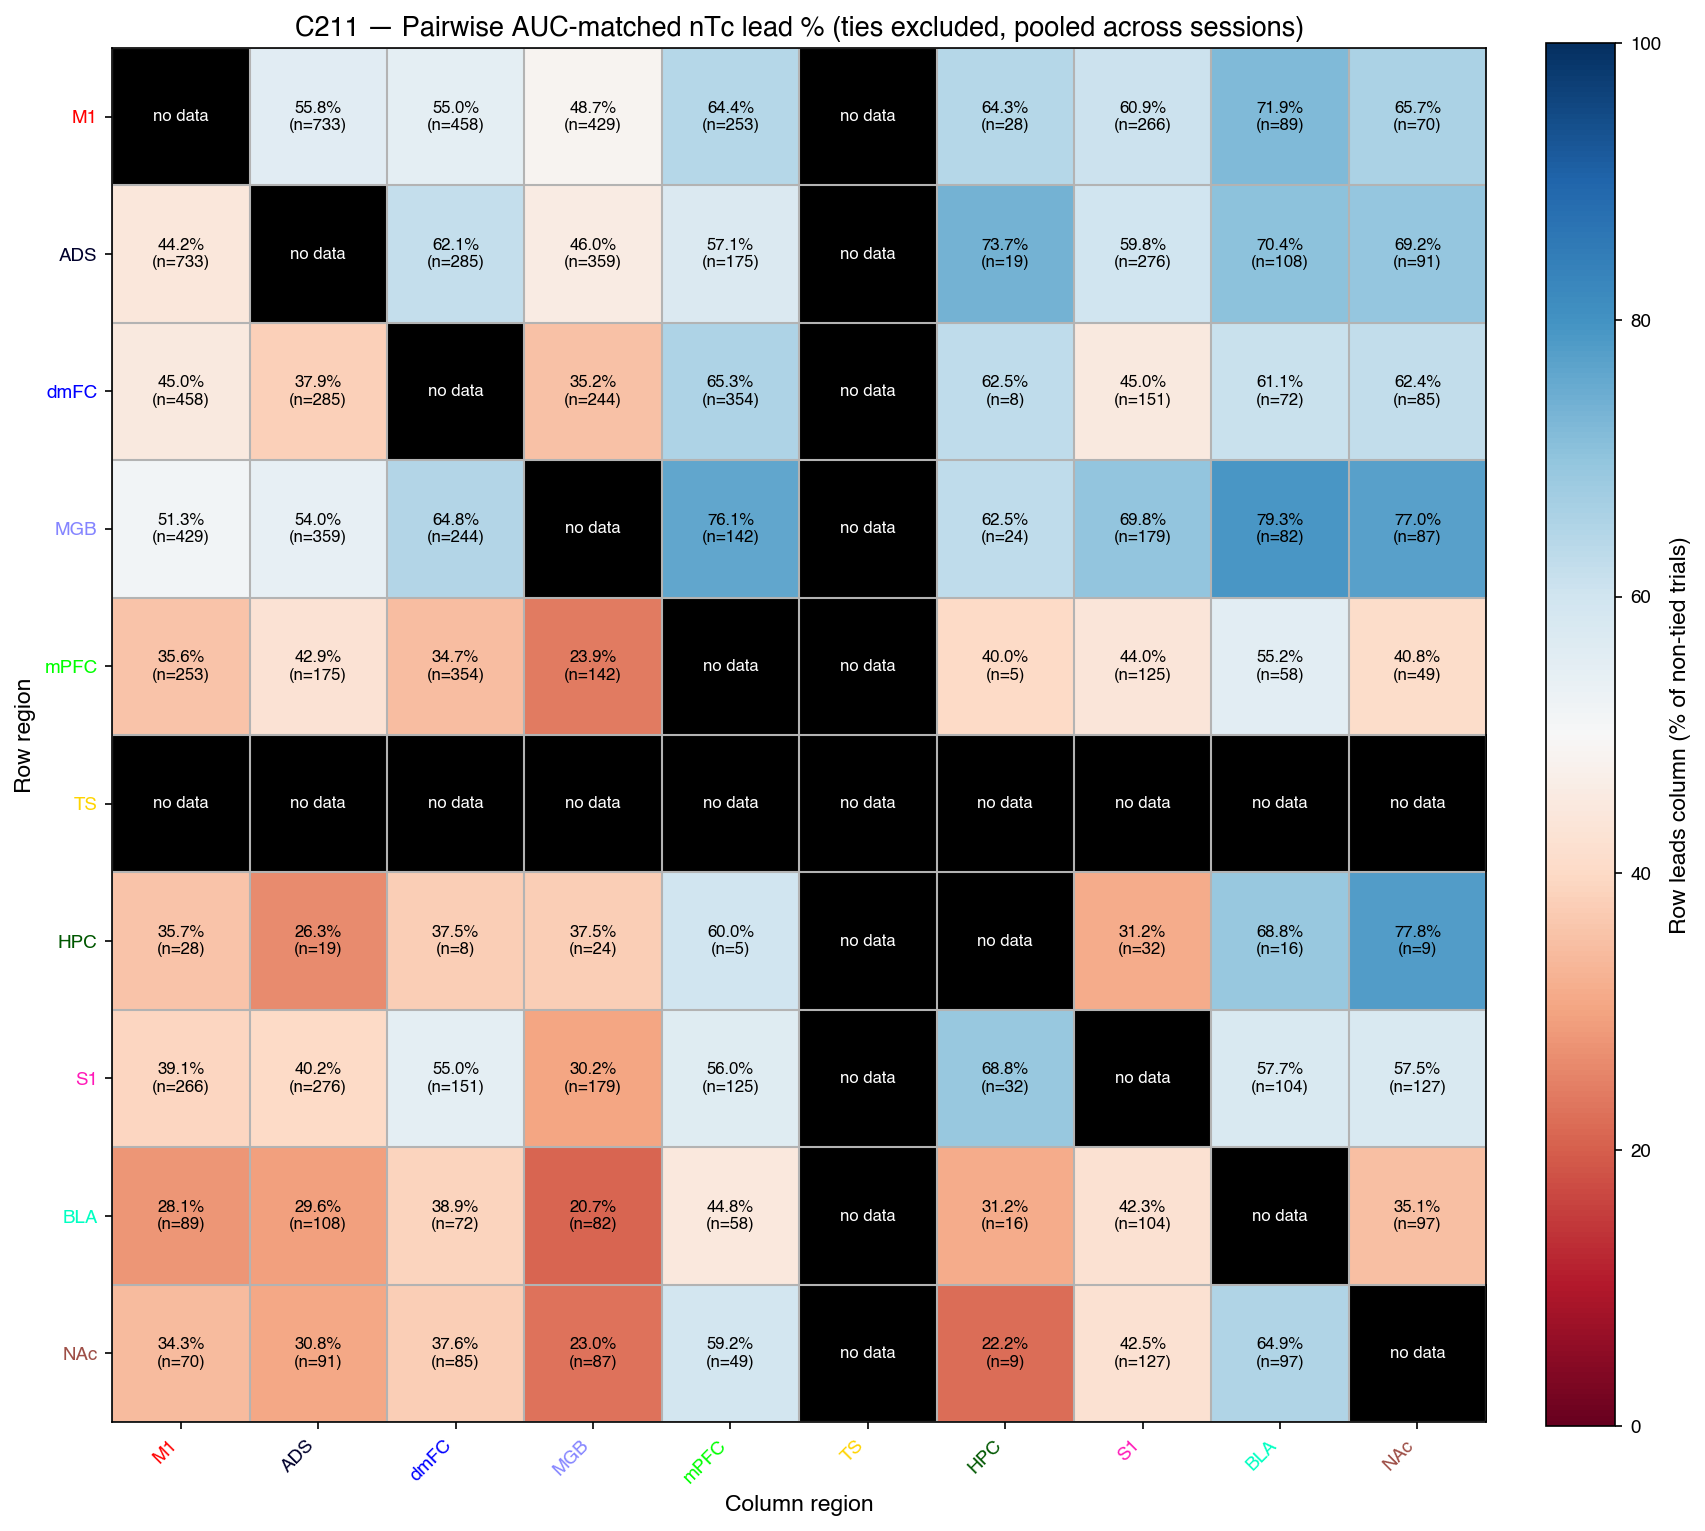

Saved: figures/pairwise_aucmatched_ntc_lead_heatmap_animal_C211.svg


In [14]:
animal_results = {}

for animal in ALL_ANIMALS:
    (
        lead_pct_matrix, overlap_count_matrix, nontied_count_matrix,
        lead_count_matrix, tie_count_matrix, tie_pct_matrix,
    ) = compute_pairwise_lead_matrices(animal, "animal")

    # Skip animals with no off-diagonal data
    off_diag_mask = ~np.eye(len(lead_pct_matrix), dtype=bool)
    if not lead_pct_matrix.where(off_diag_mask).notna().any().any():
        print(f"Skipping {animal}: no pairwise data for this animal.")
        continue

    animal_results[animal] = {
        "lead_pct_matrix":      lead_pct_matrix,
        "overlap_count_matrix": overlap_count_matrix,
        "nontied_count_matrix": nontied_count_matrix,
        "lead_count_matrix":    lead_count_matrix,
        "tie_count_matrix":     tie_count_matrix,
        "tie_pct_matrix":       tie_pct_matrix,
    }

    title = (
        f"{animal} — Pairwise AUC-matched nTc lead %"
        f" (ties excluded, pooled across sessions)"
    )
    fig = plot_pairwise_heatmap(
        lead_pct_matrix, nontied_count_matrix, title,
        colorbar_label="Row leads column (% of non-tied trials)",
        annotation_fn=_format_lead_annotation,
    )
    output_path = FIG_DIR / f"pairwise_aucmatched_ntc_lead_heatmap_animal_{animal}.svg"
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    print(f"Saved: {output_path}")

## Per-animal tie-percentage heatmaps

Each cell shows the percentage of all overlapping AUC-matched trials on
which the two regions had identical commitment times.

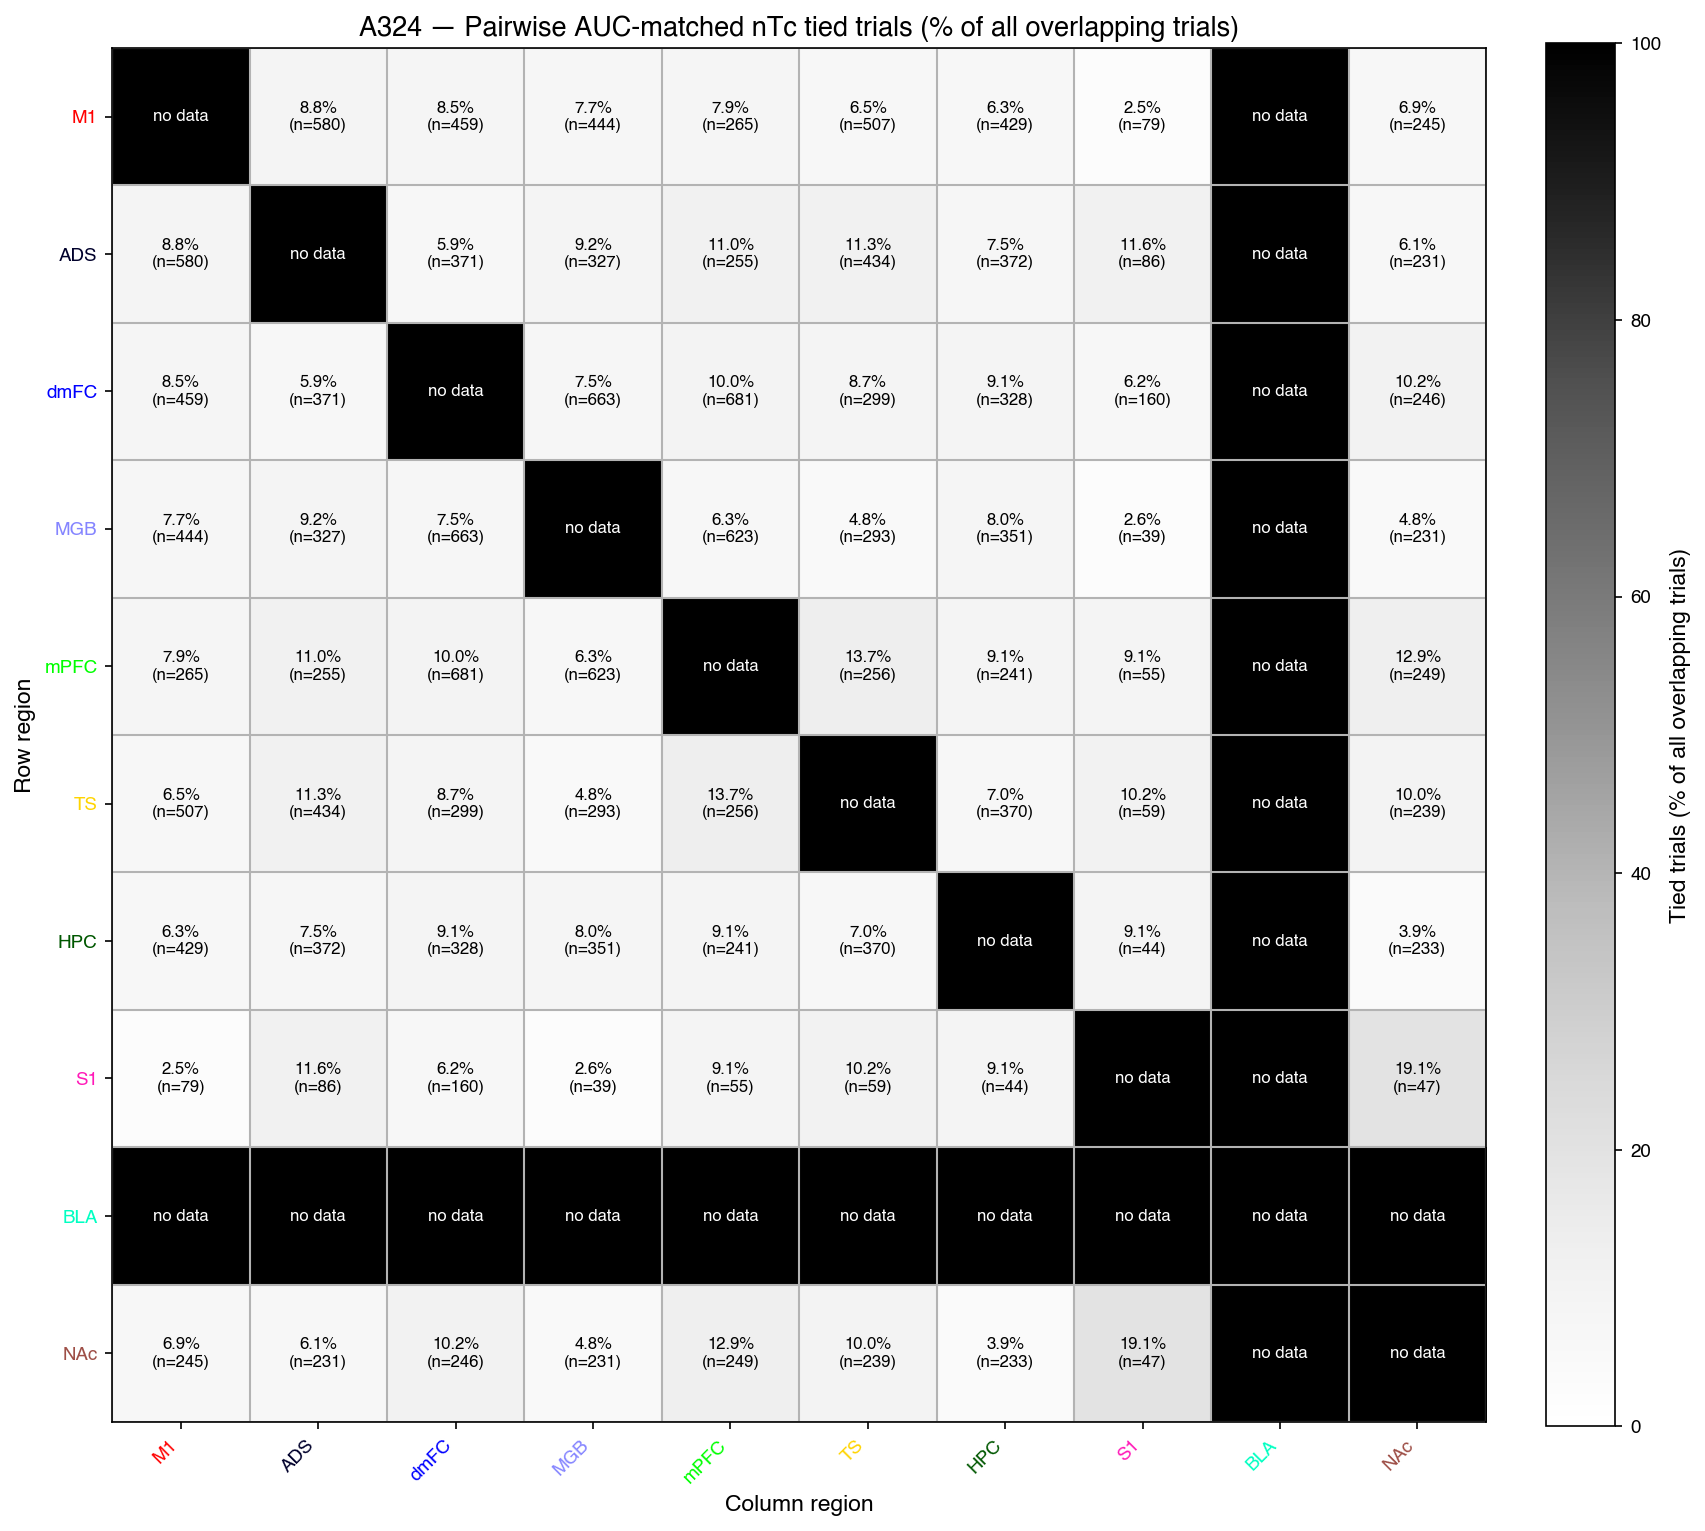

Saved: figures/pairwise_aucmatched_ntc_tie_heatmap_animal_A324.svg


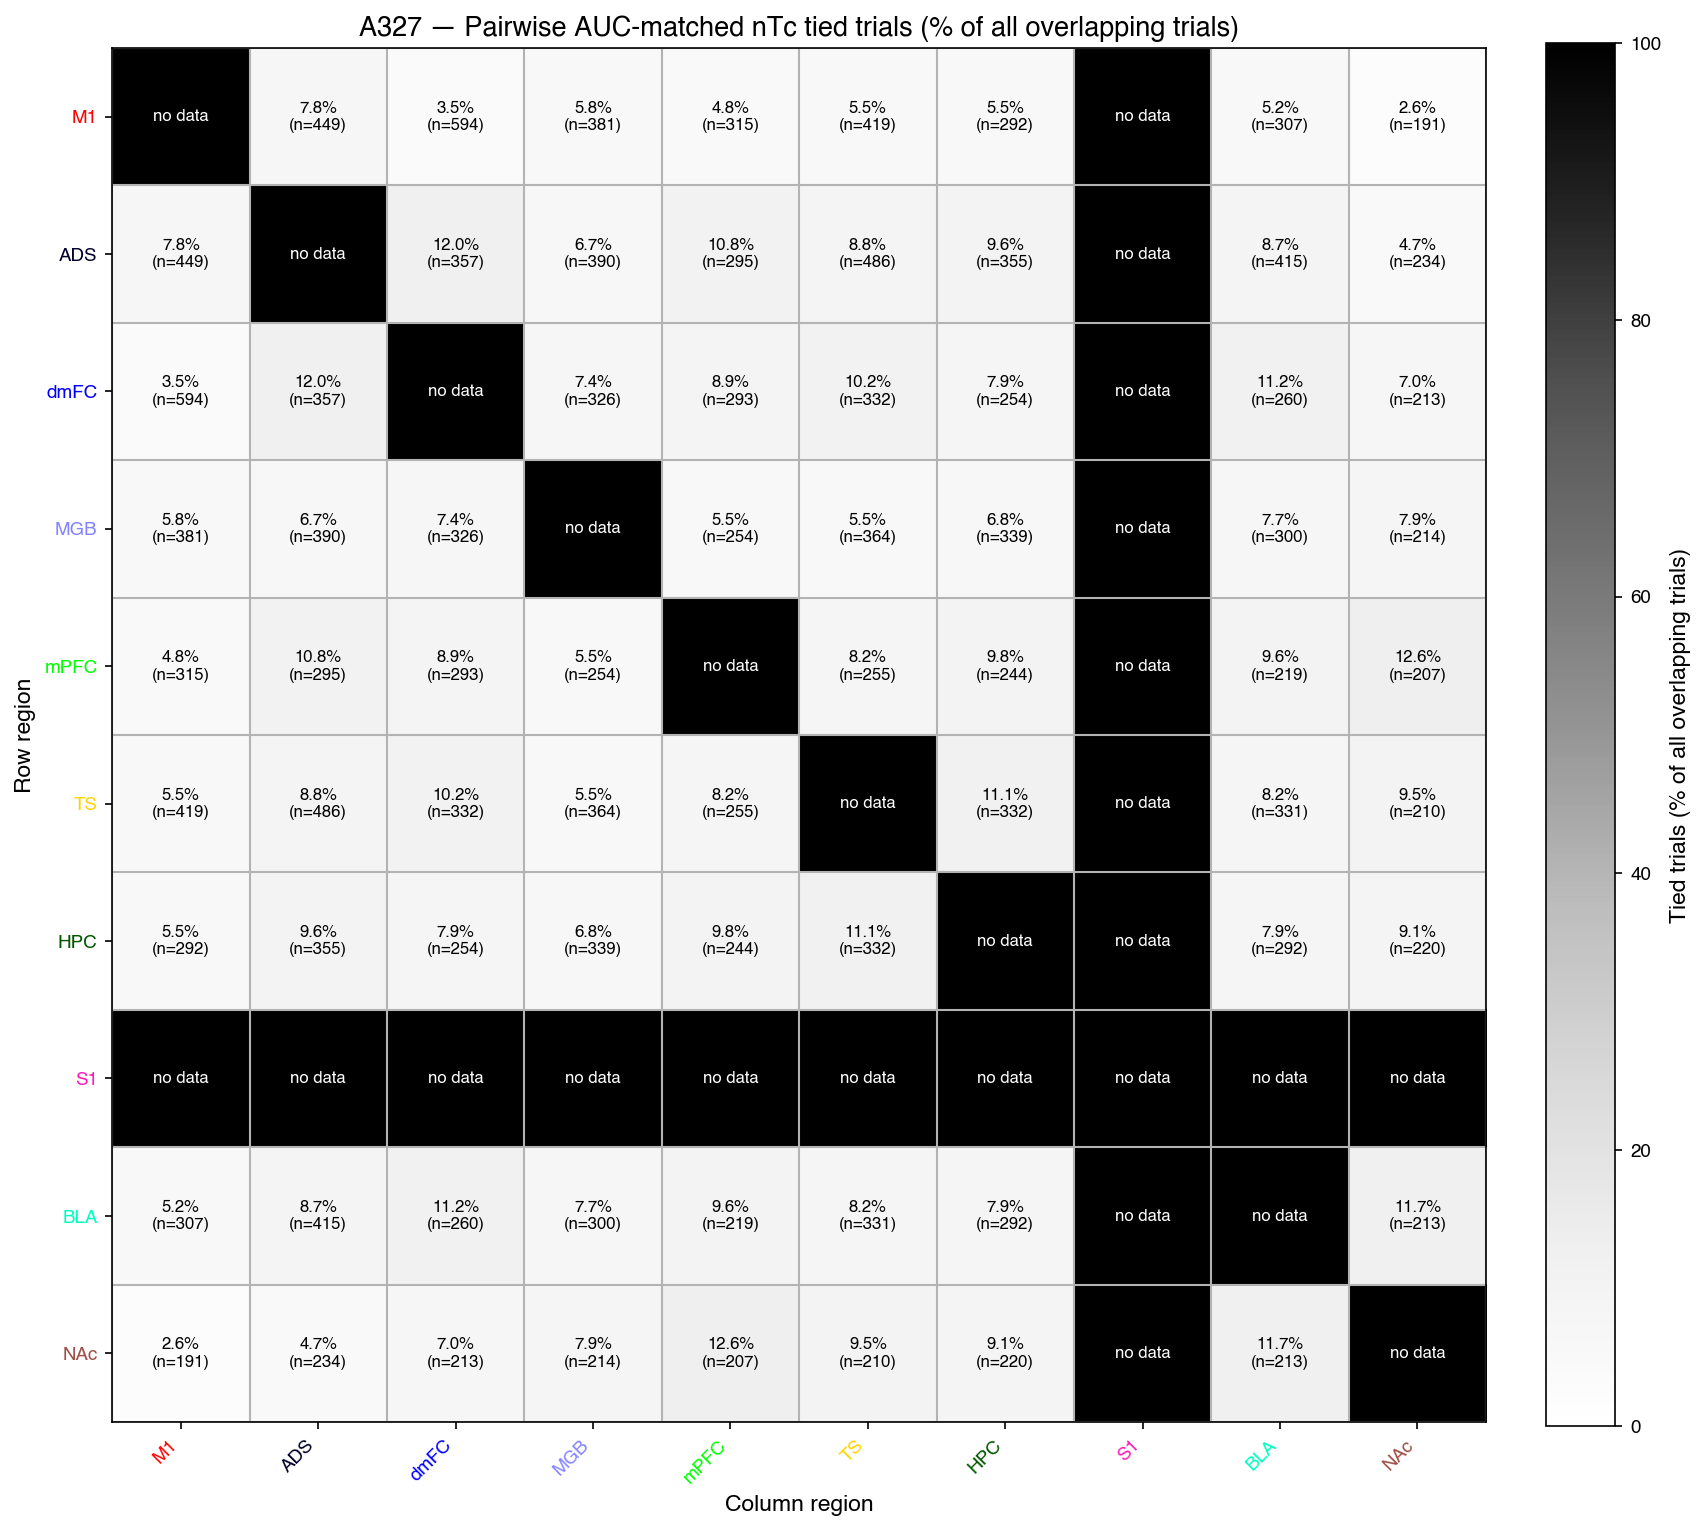

Saved: figures/pairwise_aucmatched_ntc_tie_heatmap_animal_A327.svg


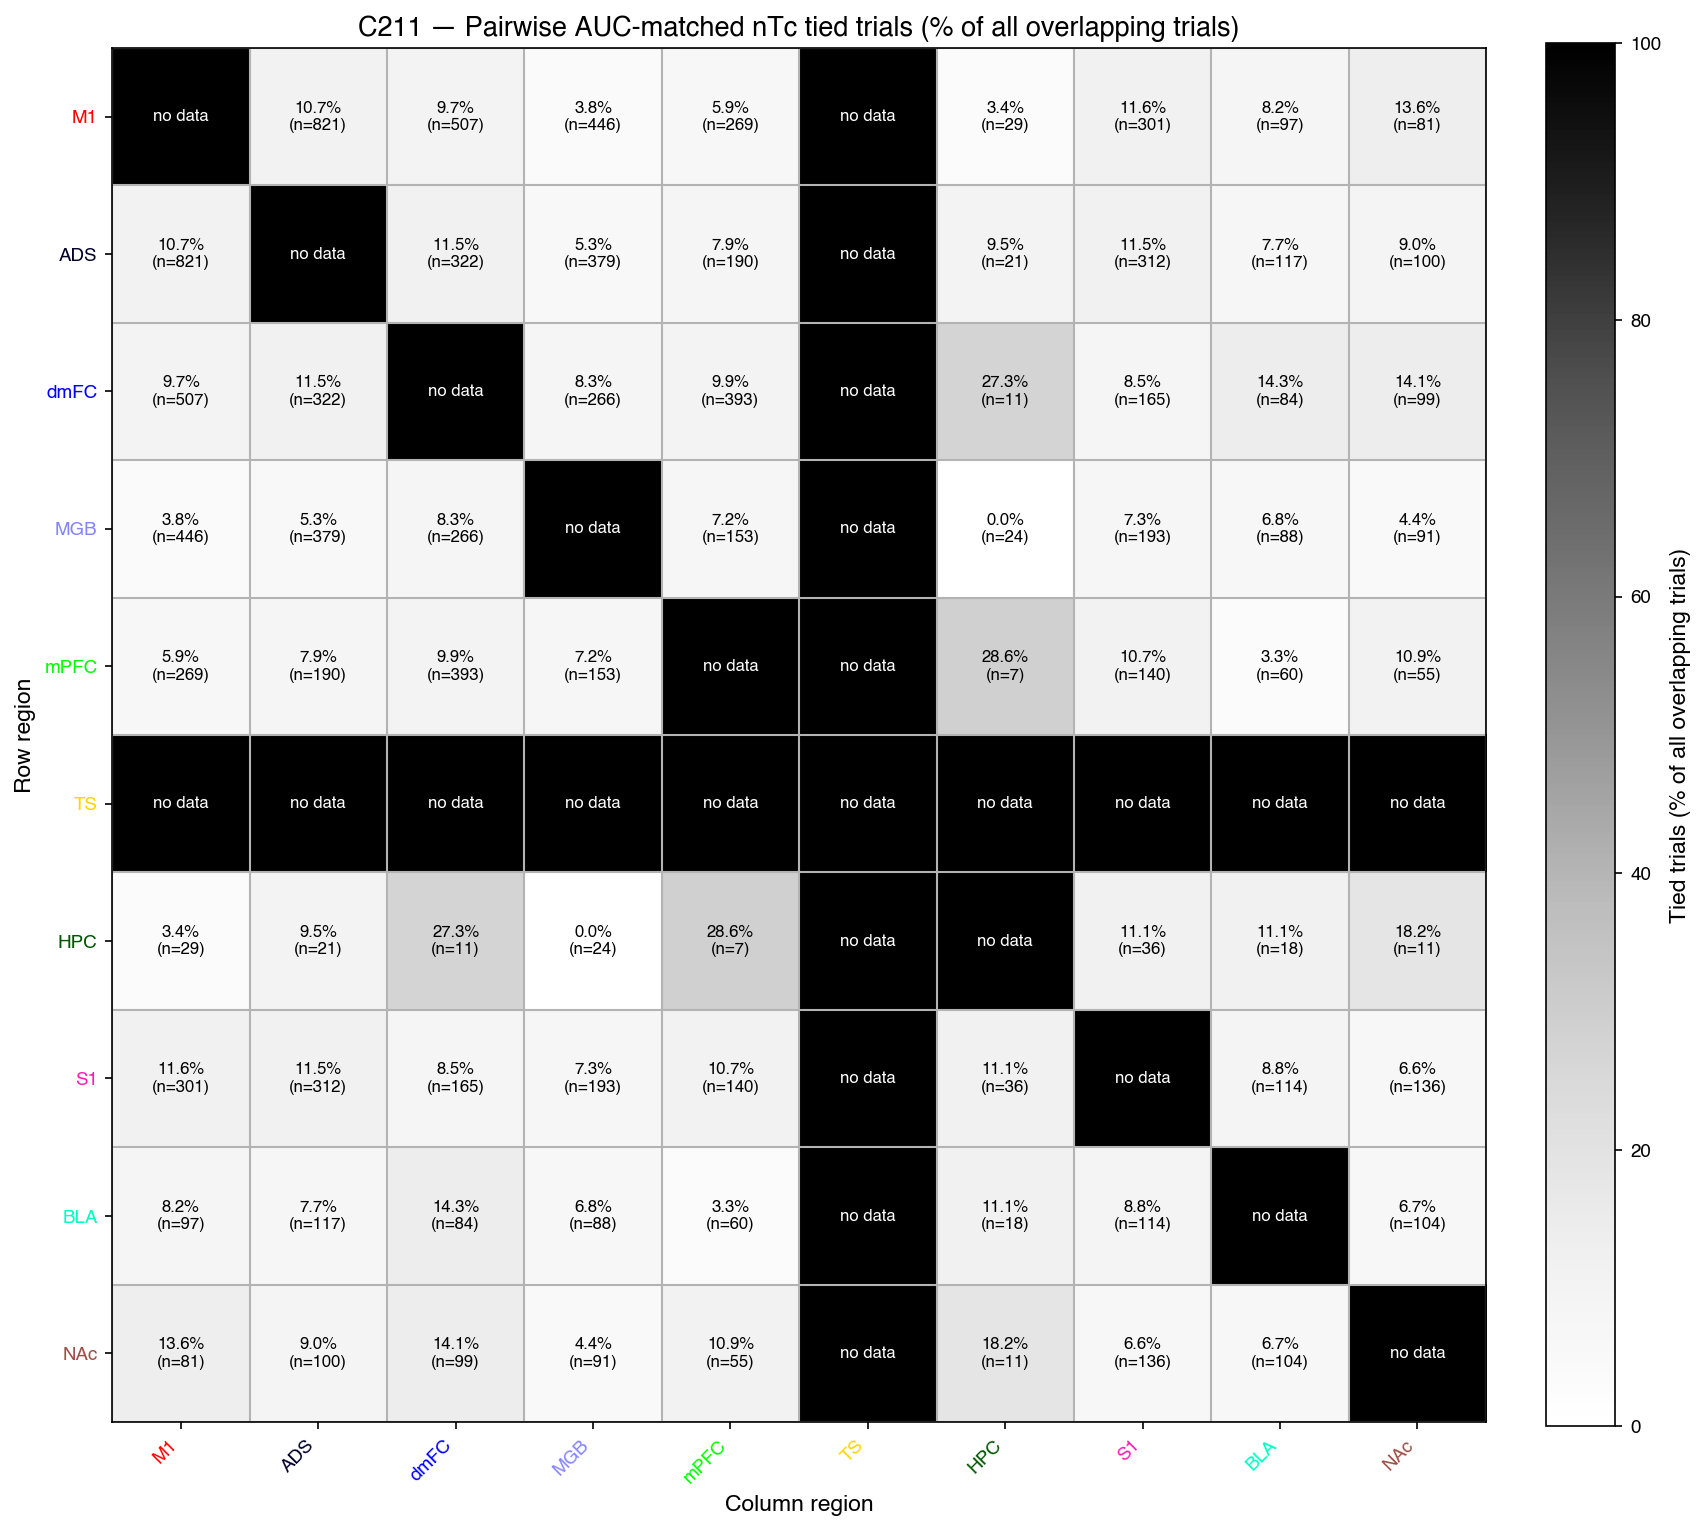

Saved: figures/pairwise_aucmatched_ntc_tie_heatmap_animal_C211.svg


In [15]:
for animal in ALL_ANIMALS:
    if animal not in animal_results:
        continue

    tie_pct_matrix       = animal_results[animal]["tie_pct_matrix"]
    overlap_count_matrix = animal_results[animal]["overlap_count_matrix"]

    title = (
        f"{animal} — Pairwise AUC-matched nTc tied trials"
        f" (% of all overlapping trials)"
    )
    fig = plot_pairwise_heatmap(
        tie_pct_matrix, overlap_count_matrix, title,
        colorbar_label="Tied trials (% of all overlapping trials)",
        annotation_fn=_format_tie_annotation,
        cmap="Greys",
    )
    output_path = FIG_DIR / f"pairwise_aucmatched_ntc_tie_heatmap_animal_{animal}.svg"
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    print(f"Saved: {output_path}")

## Sanity checks

Verify the internal consistency of the computed matrices:

1. **Complementarity**: for every off-diagonal pair (A, B), `lead_pct(A, B) + lead_pct(B, A) == 100`.
2. **Count decomposition**: `n_A_leads + n_B_leads + n_ties == n_overlap` for every pair.
3. **Symmetry**: overlap counts, non-tied counts, and tie percentages are symmetric.

In [16]:
for animal in sorted(animal_results.keys()):
    res = animal_results[animal]
    lpm = res["lead_pct_matrix"]
    ovm = res["overlap_count_matrix"]
    ntm = res["nontied_count_matrix"]
    lcm = res["lead_count_matrix"]
    tcm = res["tie_count_matrix"]

    print(f"\n── {animal} ──")

    # 1. Complementarity
    for i, r1 in enumerate(lpm.index):
        for j, r2 in enumerate(lpm.columns):
            if i >= j:
                continue
            v1, v2 = lpm.loc[r1, r2], lpm.loc[r2, r1]
            if pd.notna(v1) and pd.notna(v2):
                total = v1 + v2
                status = "OK" if abs(total - 100.0) < 1e-9 else f"MISMATCH ({total:.4f})"
                print(f"  {r1:>4s} vs {r2:<4s}: {v1:6.2f} + {v2:6.2f} = {total:7.2f}  {status}")

    # 2. Count decomposition
    decomp_ok = True
    for (ra, rb) in pair_tables:
        if ra not in lpm.index or rb not in lpm.columns:
            continue
        o = ovm.loc[ra, rb]
        if o > 0:
            a_l = lcm.loc[ra, rb]
            b_l = lcm.loc[rb, ra]
            t   = tcm.loc[ra, rb]
            if a_l + b_l + t != o:
                print(f"  DECOMPOSITION FAIL: {ra}–{rb}: {a_l}+{b_l}+{t} != {o}")
                decomp_ok = False
    if decomp_ok:
        print(f"  Count decomposition (leads + ties == overlap): OK for all pairs")

    # 3. Symmetry
    sym_ok = True
    for r1 in ovm.index:
        for r2 in ovm.columns:
            if ovm.loc[r1, r2] != ovm.loc[r2, r1]:
                print(f"  SYMMETRY FAIL: overlap {r1},{r2}")
                sym_ok = False
            if ntm.loc[r1, r2] != ntm.loc[r2, r1]:
                print(f"  SYMMETRY FAIL: nontied {r1},{r2}")
                sym_ok = False
    if sym_ok:
        print(f"  Symmetry (overlap, nontied counts): OK")


── A324 ──
    M1 vs ADS :  58.60 +  41.40 =  100.00  OK
    M1 vs dmFC:  60.00 +  40.00 =  100.00  OK
    M1 vs MGB :  62.44 +  37.56 =  100.00  OK
    M1 vs mPFC:  66.80 +  33.20 =  100.00  OK
    M1 vs TS  :  70.25 +  29.75 =  100.00  OK
    M1 vs HPC :  48.76 +  51.24 =  100.00  OK
    M1 vs S1  :  83.12 +  16.88 =  100.00  OK
    M1 vs NAc :  68.42 +  31.58 =  100.00  OK
   ADS vs dmFC:  67.62 +  32.38 =  100.00  OK
   ADS vs MGB :  59.26 +  40.74 =  100.00  OK
   ADS vs mPFC:  64.76 +  35.24 =  100.00  OK
   ADS vs TS  :  58.70 +  41.30 =  100.00  OK
   ADS vs HPC :  55.52 +  44.48 =  100.00  OK
   ADS vs S1  :  78.95 +  21.05 =  100.00  OK
   ADS vs NAc :  73.27 +  26.73 =  100.00  OK
  dmFC vs MGB :  44.05 +  55.95 =  100.00  OK
  dmFC vs mPFC:  70.96 +  29.04 =  100.00  OK
  dmFC vs TS  :  53.48 +  46.52 =  100.00  OK
  dmFC vs HPC :  41.61 +  58.39 =  100.00  OK
  dmFC vs S1  :  80.00 +  20.00 =  100.00  OK
  dmFC vs NAc :  71.95 +  28.05 =  100.00  OK
   MGB vs mPFC:  62.84

## Quick inspection

In [17]:
example_animal = sorted(animal_results.keys())[0]

print(f"{example_animal} — lead % matrix (ties excluded):")
animal_results[example_animal]["lead_pct_matrix"]

A324 — lead % matrix (ties excluded):


,M1,ADS,dmFC,MGB,mPFC,TS,HPC,S1,BLA,NAc
M1,NaN,58.601134,60.000000,62.439024,66.803279,70.253165,48.756219,83.116883,NaN,68.421053
ADS,41.398866,NaN,67.621777,59.259259,64.757709,58.701299,55.523256,78.947368,NaN,73.271889
dmFC,40.000000,32.378223,NaN,44.045677,70.962480,53.479853,41.610738,80.000000,NaN,71.945701
MGB,37.560976,40.740741,55.954323,NaN,62.842466,66.666667,53.869969,92.105263,NaN,74.090909
mPFC,33.196721,35.242291,29.037520,37.157534,NaN,41.176471,27.397260,80.000000,NaN,65.898618
TS,29.746835,41.298701,46.520147,33.333333,58.823529,NaN,45.348837,81.132075,NaN,71.162791
HPC,51.243781,44.476744,58.389262,46.130031,72.602740,54.651163,NaN,80.000000,NaN,75.892857
S1,16.883117,21.052632,20.000000,7.894737,20.000000,18.867925,20.000000,NaN,NaN,47.368421
BLA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NAc,31.578947,26.728111,28.054299,25.909091,34.101382,28.837209,24.107143,52.631579,NaN,NaN


In [18]:
print(f"{example_animal} — tie % matrix:")
animal_results[example_animal]["tie_pct_matrix"]

A324 — tie % matrix:


,M1,ADS,dmFC,MGB,mPFC,TS,HPC,S1,BLA,NAc
M1,NaN,8.793103,8.496732,7.657658,7.924528,6.508876,6.293706,2.531646,NaN,6.938776
ADS,8.793103,NaN,5.929919,9.174312,10.980392,11.290323,7.526882,11.627907,NaN,6.060606
dmFC,8.496732,5.929919,NaN,7.541478,9.985316,8.695652,9.146341,6.250000,NaN,10.162602
MGB,7.657658,9.174312,7.541478,NaN,6.260032,4.778157,7.977208,2.564103,NaN,4.761905
mPFC,7.924528,10.980392,9.985316,6.260032,NaN,13.671875,9.128631,9.090909,NaN,12.851406
TS,6.508876,11.290323,8.695652,4.778157,13.671875,NaN,7.027027,10.169492,NaN,10.041841
HPC,6.293706,7.526882,9.146341,7.977208,9.128631,7.027027,NaN,9.090909,NaN,3.862661
S1,2.531646,11.627907,6.250000,2.564103,9.090909,10.169492,9.090909,NaN,NaN,19.148936
BLA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NAc,6.938776,6.060606,10.162602,4.761905,12.851406,10.041841,3.862661,19.148936,NaN,NaN
